# Cell fate decision

This notebook reproduces the analysis of the cell fate model of the [MaBoSS website](https://maboss.curie.fr).

The model is based on a published Boolean model ([Calzone et al., 2010](https://doi.org/10.1371/journal.pcbi.1000702)).
It describes how a cell chooses between three different fates, apoptosis, survival (NFκB activation) and
necroptosis (non-apoptotic cell death, NonACD), in response to the engagement of death receptors (here TNF).

Mutants are included in the model as external variables: `$gene_del` for a deletion and `$gene_oe` for an
over-expression. They are set to 0 for the wild type, and to 1 to simulate the mutant.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `CellFateModel.bnd` and
`CellFateModel.cfg`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## The model

Only the three phenotype nodes, `Apoptosis`, `Survival` and `NonACD`, are output nodes: all the other nodes
are internal. The mutant parameters are all set to 0 in the configuration file (wild type).

In [2]:
model = maboss.load("CellFateModel.bnd", "CellFateModel.cfg")
print("Output nodes:", ", ".join(node for node in model.network if not model.network[node].is_internal))

Output nodes: NonACD, Apoptosis, Survival


## Wild type

In the wild type, survival is transiently activated, before most of the cells die by apoptosis.

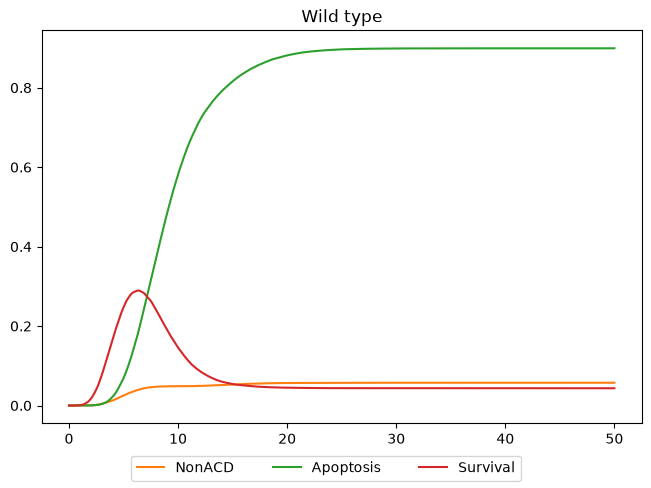

In [3]:
result_wt = model.run()
result_wt.plot_node_trajectory(until=50)
plt.title("Wild type")
legend_below()
plt.savefig("figures/cellfate_wt_trajectories.png")

The three phenotypes are reachable, as in the published model. The probabilities differ slightly from the
published ones: they are not absolute values, as they depend on the computation and on the details of the
model (in the published model, the trajectories were computed over the transition graph).

The final distribution of the phenotypes (`<nil>` is the state where no phenotype node is active):

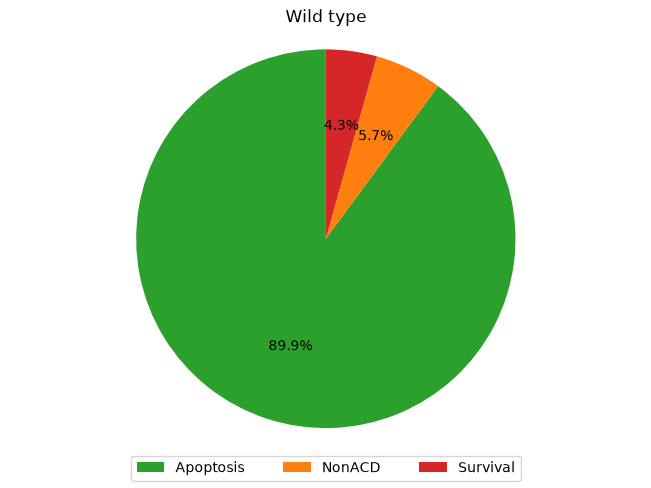

In [4]:
result_wt.plot_piechart()
plt.title("Wild type")
legend_below()
plt.savefig("figures/cellfate_wt.png")

## Mutants

A mutant is simulated by setting its parameter to 1. The deletion of CASP8 leads to the disappearance of
apoptosis, in accordance with published experiments.

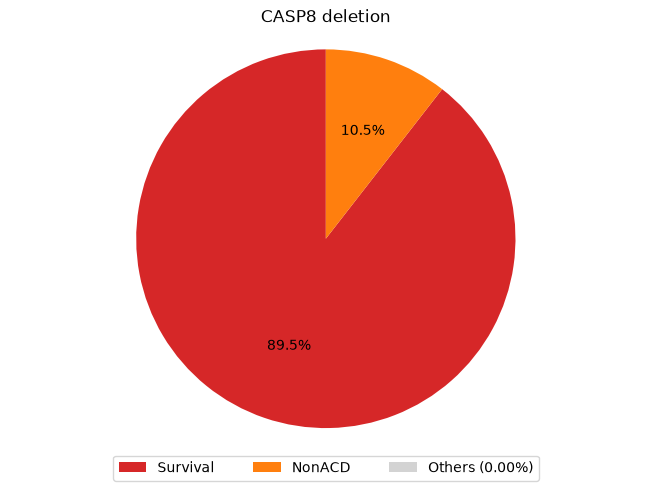

In [5]:
casp8_del = model.copy()
casp8_del.param["$CASP8_del"] = 1
result_casp8_del = casp8_del.run()
result_casp8_del.plot_piechart()
plt.title("CASP8 deletion")
legend_below()
plt.savefig("figures/cellfate_casp8_del.png")

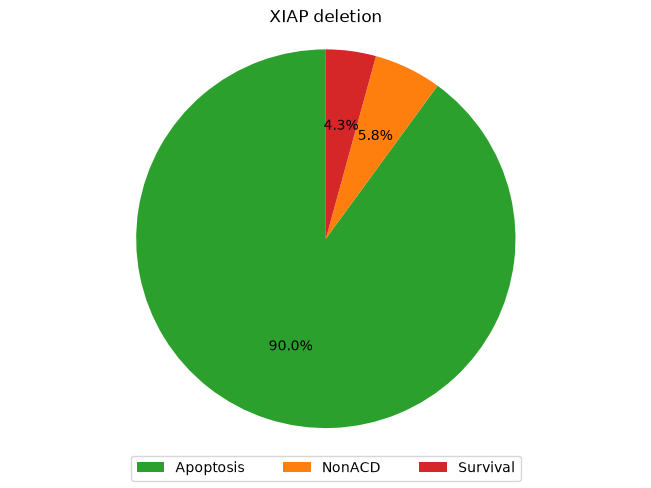

In [6]:
xiap_del = model.copy()
xiap_del.param["$XIAP_del"] = 1
result_xiap_del = xiap_del.run()
result_xiap_del.plot_piechart()
plt.title("XIAP deletion")
legend_below()
plt.savefig("figures/cellfate_xiap_del.png")